In [1]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

dataset = pd.read_csv("titanic.csv")
print(dataset)

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

In [2]:
test_dataset = pd.read_csv("titanic_test.csv")
print(test_dataset)

     PassengerId  Pclass                                          Name  \
0            892       3                              Kelly, Mr. James   
1            893       3              Wilkes, Mrs. James (Ellen Needs)   
2            894       2                     Myles, Mr. Thomas Francis   
3            895       3                              Wirz, Mr. Albert   
4            896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)   
..           ...     ...                                           ...   
413         1305       3                            Spector, Mr. Woolf   
414         1306       1                  Oliva y Ocana, Dona. Fermina   
415         1307       3                  Saether, Mr. Simon Sivertsen   
416         1308       3                           Ware, Mr. Frederick   
417         1309       3                      Peter, Master. Michael J   

        Sex   Age  SibSp  Parch              Ticket      Fare Cabin Embarked  
0      male  34.5      0      0 

In [3]:
train_data = dataset[["Sex", "Age", "Pclass", "Fare"]].copy()

# Cek missing value sebelum pengisian
print("Missing value Age sebelum:")
print(train_data["Age"].isnull().sum())

# Isi Age berdasarkan rata-rata Age masing-masing Pclass
train_data["Age"] = train_data.groupby("Pclass")["Age"].transform(
    lambda x: x.fillna(x.mean())
)

print("\nMissing value Age sesudah:")
print(train_data["Age"].isnull().sum())

print(train_data)

Missing value Age sebelum:
177

Missing value Age sesudah:
0
        Sex       Age  Pclass     Fare
0      male  22.00000       3   7.2500
1    female  38.00000       1  71.2833
2    female  26.00000       3   7.9250
3    female  35.00000       1  53.1000
4      male  35.00000       3   8.0500
..      ...       ...     ...      ...
886    male  27.00000       2  13.0000
887  female  19.00000       1  30.0000
888  female  25.14062       3  23.4500
889    male  26.00000       1  30.0000
890    male  32.00000       3   7.7500

[891 rows x 4 columns]


In [4]:
test_data = test_dataset[["Sex", "Age", "Pclass", "Fare"]].copy()

# Gunakan mean Age dari TRAIN berdasarkan Pclass
age_mean_by_class = train_data.groupby("Pclass")["Age"].mean()

for pclass in age_mean_by_class.index:
    test_data.loc[
        (test_data["Pclass"] == pclass) & (test_data["Age"].isnull()),
        "Age"
    ] = age_mean_by_class[pclass]

print(test_data)

        Sex       Age  Pclass      Fare
0      male  34.50000       3    7.8292
1    female  47.00000       3    7.0000
2      male  62.00000       2    9.6875
3      male  27.00000       3    8.6625
4    female  22.00000       3   12.2875
..      ...       ...     ...       ...
413    male  25.14062       3    8.0500
414  female  39.00000       1  108.9000
415    male  38.50000       3    7.2500
416    male  25.14062       3    8.0500
417    male  25.14062       3   22.3583

[418 rows x 4 columns]


In [5]:
train_label = dataset["Survived"].copy()

print(train_label)

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64


In [6]:
test_label = pd.read_csv("titanic_testlabel.csv")

print(test_label.columns)

if "Survived" in test_label.columns:
    test_label = test_label["Survived"]
else:
    test_label = test_label.iloc[:, 0]


Index(['PassengerId', 'Survived'], dtype='object')


In [ ]:
# Encoding Sex
encoder = LabelEncoder()

train_data["Sex"] = encoder.fit_transform(train_data["Sex"])
test_data["Sex"] = encoder.transform(test_data["Sex"])

# Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(train_data, train_label)

train_prediction = model.predict(train_data)

train_error_count = np.sum(train_prediction != train_label)
train_error_ratio = train_error_count / len(train_label)

print("=== TRAINING ===")
print("Jumlah data :", len(train_label))
print("Salah       :", train_error_count)
print("Error ratio :", train_error_ratio)

# Prediksi
test_prediction = model.predict(test_data)

# Hitung Error Ratio
error_count = np.sum(test_prediction != test_label)
total_test = len(test_label)

error_ratio = error_count / total_test

print("=== HASIL KLASIFIKASI ===")
print("Jumlah data test      :", total_test)
print("Jumlah prediksi salah :", error_count)
print("Error ratio           :", error_ratio)
print("Error ratio (%)       :", error_ratio * 100, "%")

=== TRAINING ===
Jumlah data : 891
Salah       : 18
Error ratio : 0.020202020202020204
=== HASIL KLASIFIKASI ===
Jumlah data test      : 418
Jumlah prediksi salah : 86
Error ratio           : 0.20574162679425836
Error ratio (%)       : 20.574162679425836 %


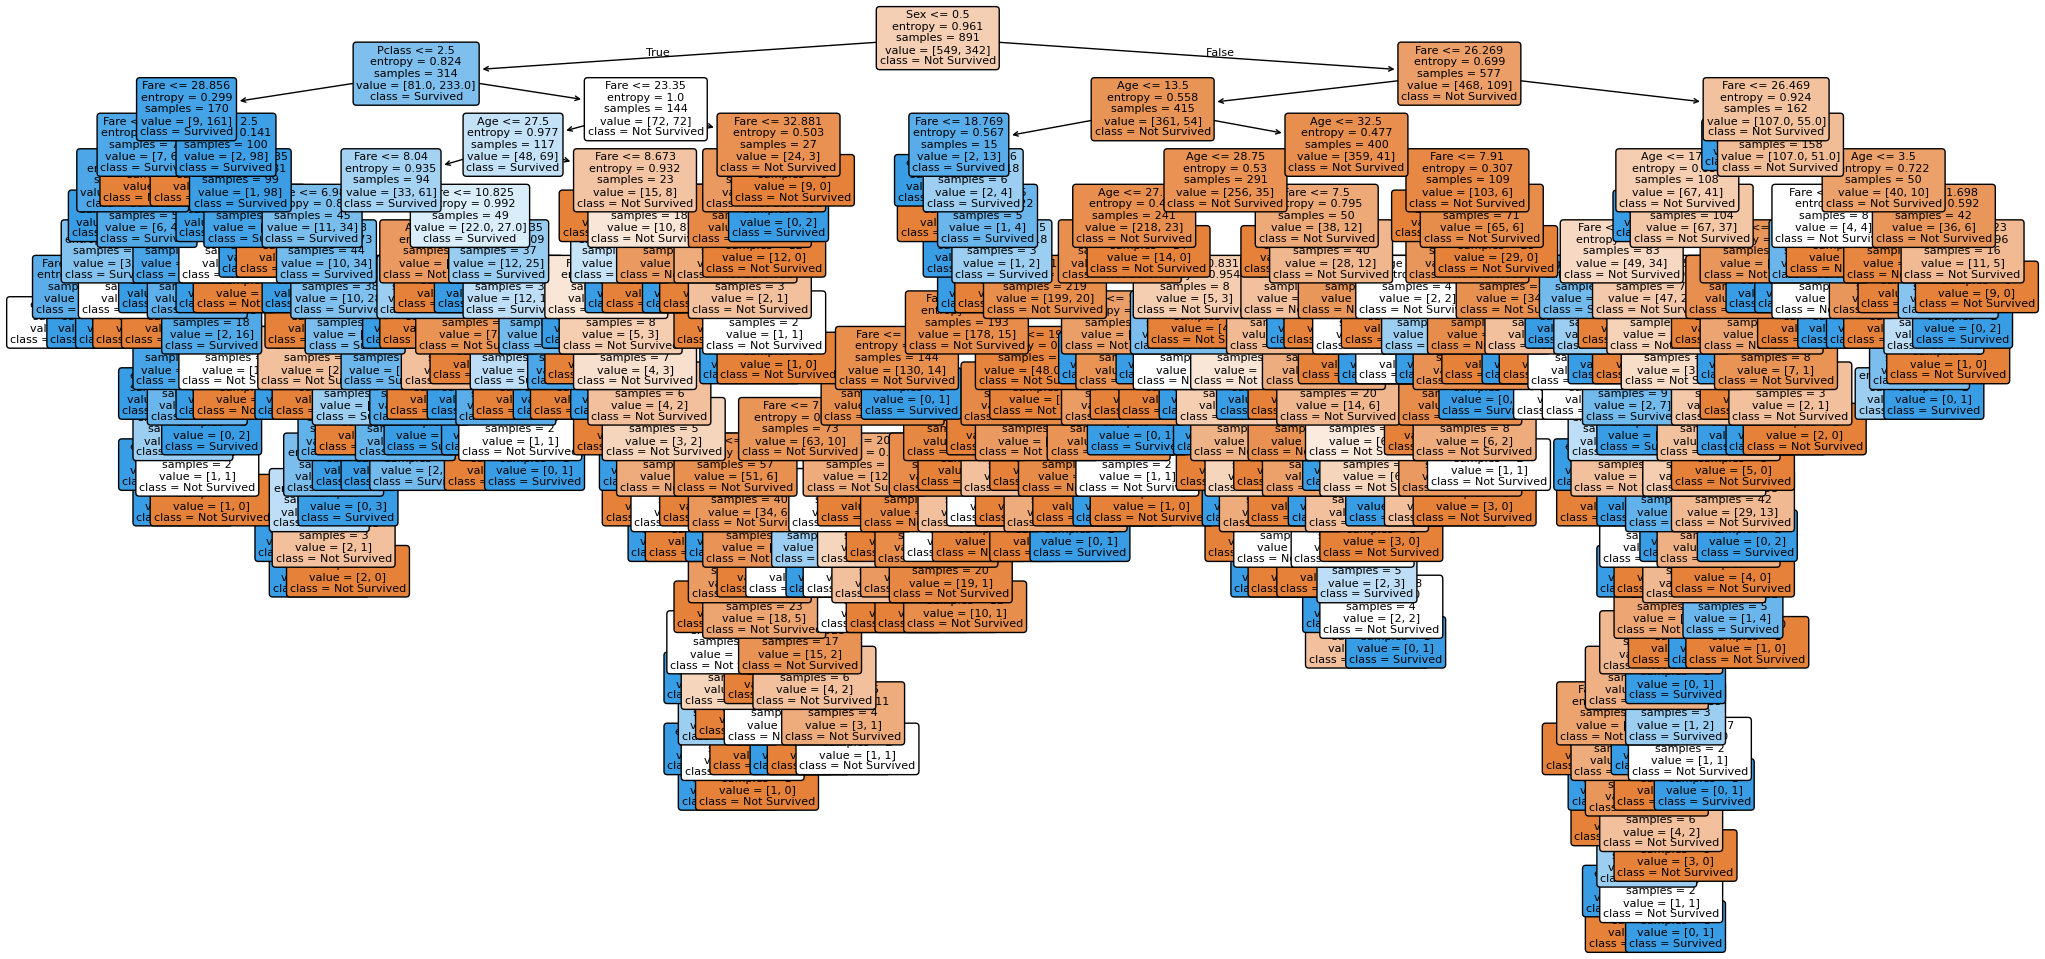

In [8]:
# 10. Tampilkan Hirarki Decision Tree
plt.figure(figsize=(25, 12))

plot_tree(
    model,
    feature_names=["Sex", "Age", "Pclass", "Fare"],
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()